# 09 -- Boosting models (XGBoost, LightGBM, CatBoost, GradientBoosting)

Gradient boosting usually gives the best PD discrimination on tabular
credit data. This notebook:

1. Plots true per-iteration train/validation **loss curves** for all four
   libraries (early-stopping view).
2. Tunes each with `GridSearchCV` (compact, realistic grids).
3. Compares the four on the untouched holdout and inspects importance.

`scale_pos_weight` handles the ~8% default rate. Grids are intentionally
small; widen them or lower `SEARCH_FRAC` runtime permitting.

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.modeling import (
    classification_metrics,
    cv_results_frame,
    evaluate_split,
    load_modeling_data,
    make_pipeline,
    metrics_frame,
    run_grid_search,
    subsample,
    train_valid_report,
)
from src.modeling import plots

data = load_modeling_data()
pd.Series(data.summary())


n_train                246005.0000
n_holdout               61502.0000
n_features                 52.0000
train_target_rate           0.0807
holdout_target_rate         0.0807
n_folds                     5.0000
pos_weight                 11.3900
dtype: float64

In [2]:
# Fraction of the TRAIN partition used for GridSearchCV. The holdout is never
# touched during tuning. Lower this (e.g. 0.3) for faster iteration, then set
# back to 1.0 to confirm the final model on the full training data.
SEARCH_FRAC = 0.3
search = subsample(data, frac=SEARCH_FRAC)
pd.Series(search.summary())


n_train                73802.0000
n_holdout              61502.0000
n_features                52.0000
train_target_rate          0.0807
holdout_target_rate        0.0807
n_folds                    5.0000
pos_weight                11.3900
dtype: float64

## Per-iteration loss curves

Each model is fit once on a train/validation split with log loss recorded
every boosting round. The green line marks the best (minimum validation)
iteration - where early stopping would halt.

[LightGBM] [Info] Number of positive: 5958, number of negative: 67844
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.099392 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 9291
[LightGBM] [Info] Number of data points in the train set: 73802, number of used features: 66
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080730 -> initscore=-2.432476
[LightGBM] [Info] Start training from score -2.432476


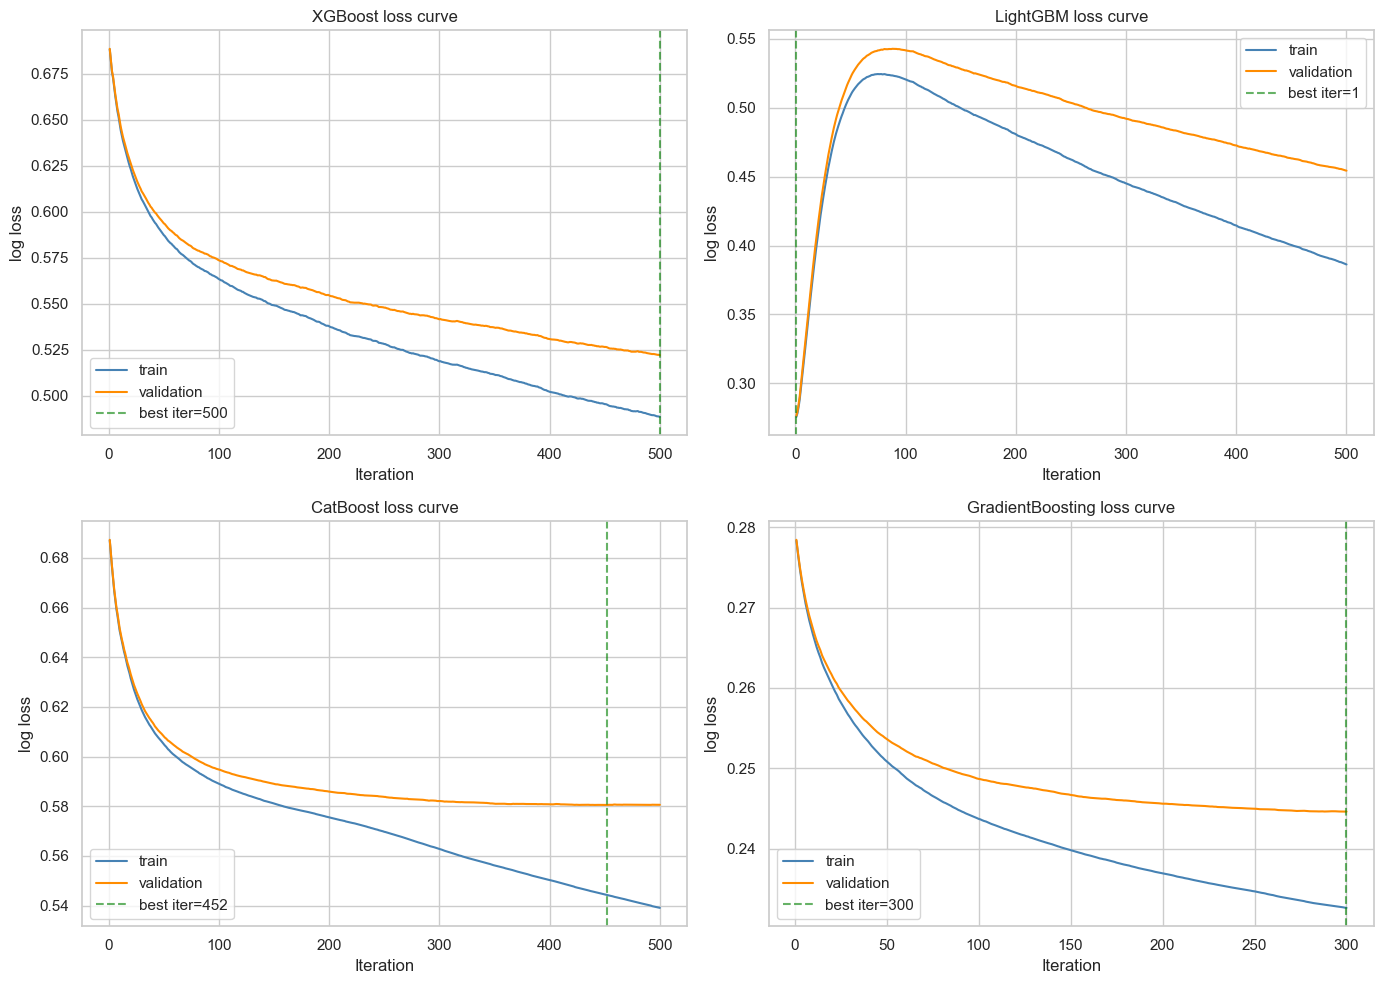

XGBoost             499
LightGBM              0
CatBoost            451
GradientBoosting    299
Name: best_iteration, dtype: int64

In [3]:
from src.modeling.boosting import (
    fit_catboost_curve,
    fit_gbm_curve,
    fit_lgbm_curve,
    fit_xgb_curve,
)

Xtr, ytr = search.X_train, search.y_train
Xva, yva = data.X_holdout, data.y_holdout

curves = {
    "XGBoost": fit_xgb_curve(Xtr, ytr, Xva, yva, num_boost_round=500),
    "LightGBM": fit_lgbm_curve(Xtr, ytr, Xva, yva, num_boost_round=500),
    "CatBoost": fit_catboost_curve(Xtr, ytr, Xva, yva, num_boost_round=500),
    "GradientBoosting": fit_gbm_curve(Xtr, ytr, Xva, yva, num_boost_round=300),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, lc) in zip(axes.ravel(), curves.items()):
    plots.plot_loss_curve(lc.train_loss, lc.valid_loss, ax=ax, title=f"{name} loss curve")
plt.tight_layout()
plt.show()

pd.Series({k: v.best_iteration for k, v in curves.items()}, name="best_iteration")

## XGBoost tuning

In [4]:
from xgboost import XGBClassifier

pos_weight = search.pos_weight
xgb = XGBClassifier(
    n_estimators=400, tree_method="hist", eval_metric="logloss",
    scale_pos_weight=pos_weight, random_state=42, n_jobs=-1,
)
xgb_grid = {
    "max_depth": [3, 4, 6],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8],
    "reg_lambda": [1.0, 5.0],
}
gs_xgb = run_grid_search(xgb, xgb_grid, search, refit="roc_auc", n_jobs=1)
cv_results_frame(gs_xgb).head(8)

Fitting 24 candidate(s) x 5 folds ...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Done in 1050.9s. Best roc_auc=0.7626
Best params: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__reg_lambda': 5.0, 'model__subsample': 0.8}


,param_model__colsample_bytree,param_model__learning_rate,param_model__max_depth,param_model__reg_lambda,param_model__subsample,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,0.8,0.03,4,5.0,0.8,0.829763,0.762574,0.005799,1
1,0.8,0.03,4,1.0,0.8,0.831680,0.761661,0.005328,2
2,0.8,0.10,3,5.0,0.8,0.848106,0.761286,0.006563,3
3,0.8,0.03,3,1.0,0.8,0.798371,0.760930,0.005369,4
4,0.8,0.03,3,5.0,0.8,0.797517,0.760786,0.005518,5
5,0.8,0.10,3,1.0,0.8,0.850455,0.760637,0.005709,6
6,0.8,0.03,4,5.0,1.0,0.828963,0.760430,0.005436,7
7,0.8,0.10,3,5.0,1.0,0.846437,0.760261,0.006907,8


## LightGBM tuning

In [5]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=500, scale_pos_weight=pos_weight,
    random_state=42, n_jobs=-1, verbose=-1,
)
lgbm_grid = {
    "num_leaves": [31, 63],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8],
    "subsample_freq": [1],
    "colsample_bytree": [0.8],
    "reg_lambda": [1.0, 5.0],
}
gs_lgbm = run_grid_search(lgbm, lgbm_grid, search, refit="roc_auc", n_jobs=1)
cv_results_frame(gs_lgbm).head(8)

Fitting 8 candidate(s) x 5 folds ...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Done in 543.3s. Best roc_auc=0.7615
Best params: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__num_leaves': 31, 'model__reg_lambda': 5.0, 'model__subsample': 0.8, 'model__subsample_freq': 1}


,param_model__colsample_bytree,param_model__learning_rate,param_model__num_leaves,param_model__reg_lambda,param_model__subsample,param_model__subsample_freq,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,0.8,0.03,31,5.0,0.8,1,0.919085,0.761460,0.004603,1
1,0.8,0.03,31,1.0,0.8,1,0.923840,0.760431,0.004276,2
2,0.8,0.03,63,5.0,0.8,1,0.977854,0.758553,0.004334,3
3,0.8,0.03,63,1.0,0.8,1,0.981586,0.757510,0.005266,4
4,0.8,0.10,31,5.0,0.8,1,0.990854,0.743156,0.006386,5
5,0.8,0.10,31,1.0,0.8,1,0.992642,0.738429,0.006405,6
6,0.8,0.10,63,5.0,0.8,1,0.999923,0.737652,0.006254,7
7,0.8,0.10,63,1.0,0.8,1,0.999969,0.731450,0.004326,8


## CatBoost tuning

In [6]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    iterations=400, scale_pos_weight=pos_weight, loss_function="Logloss",
    random_seed=42, allow_writing_files=False, verbose=False,
)
cat_grid = {
    "depth": [4, 6],
    "learning_rate": [0.03, 0.1],
    "l2_leaf_reg": [3.0, 7.0],
}
gs_cat = run_grid_search(cat, cat_grid, search, refit="roc_auc", n_jobs=1)
cv_results_frame(gs_cat).head(8)

Fitting 8 candidate(s) x 5 folds ...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Done in 752.4s. Best roc_auc=0.7616
Best params: {'model__depth': 6, 'model__l2_leaf_reg': 7.0, 'model__learning_rate': 0.03}


,param_model__depth,param_model__l2_leaf_reg,param_model__learning_rate,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,rank_test_roc_auc
0,6,7.0,0.03,0.811512,0.761551,0.006414,1
1,4,7.0,0.10,0.844978,0.760737,0.007162,2
2,6,3.0,0.03,0.814145,0.760442,0.005953,3
3,4,3.0,0.10,0.846817,0.760350,0.006518,4
4,4,3.0,0.03,0.780127,0.759848,0.005830,5
5,4,7.0,0.03,0.779484,0.759639,0.005904,6
6,6,7.0,0.10,0.919238,0.754845,0.007688,7
7,6,3.0,0.10,0.924115,0.750964,0.006204,8


## Model comparison on holdout

In [7]:
best_models = {
    "xgboost": gs_xgb.best_estimator_,
    "lightgbm": gs_lgbm.best_estimator_,
    "catboost": gs_cat.best_estimator_,
}
rows = {name: evaluate_split(m, data.X_holdout, data.y_holdout) for name, m in best_models.items()}
comparison = metrics_frame(rows).round(4).sort_values("roc_auc", ascending=False)
comparison

,roc_auc,gini,ks,pr_auc,log_loss,brier,best_f1,best_f1_threshold
catboost,0.7638,0.5275,0.4028,0.2498,0.5602,0.1893,0.3097,0.65
xgboost,0.7628,0.5257,0.3987,0.2507,0.5492,0.1851,0.3132,0.65
lightgbm,0.7615,0.5229,0.3978,0.2506,0.4944,0.1640,0.3092,0.60


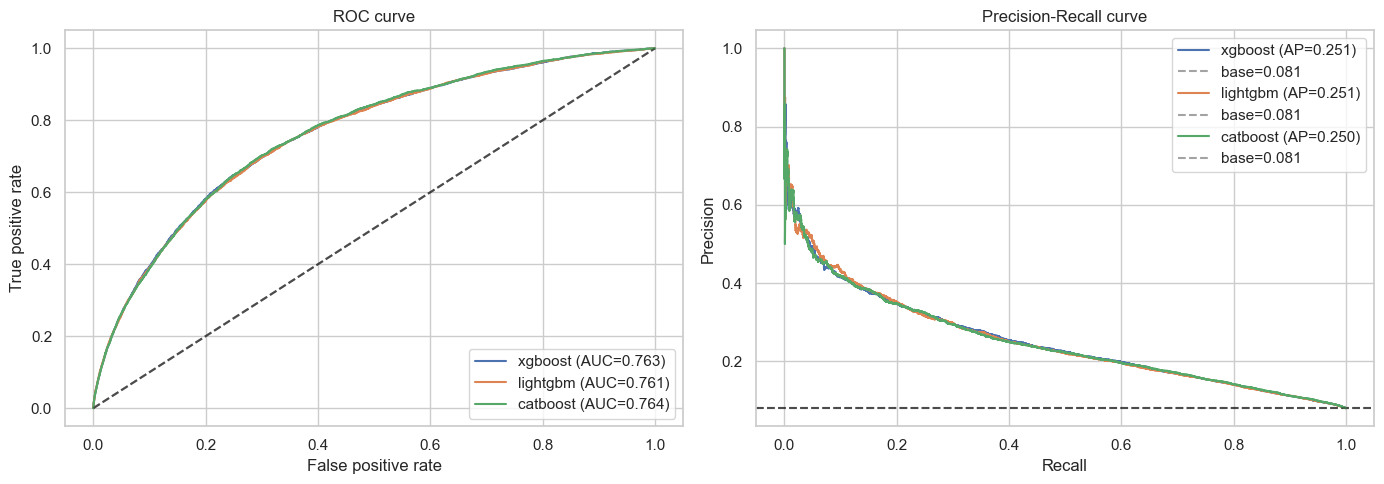

In [8]:
# Overlay ROC / PR for the tuned boosters
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, m in best_models.items():
    proba = m.predict_proba(data.X_holdout)[:, 1]
    plots.plot_roc_pr(data.y_holdout.to_numpy(), proba, label=name, axes=axes)
plt.tight_layout()
plt.show()

## Feature importance (best booster)

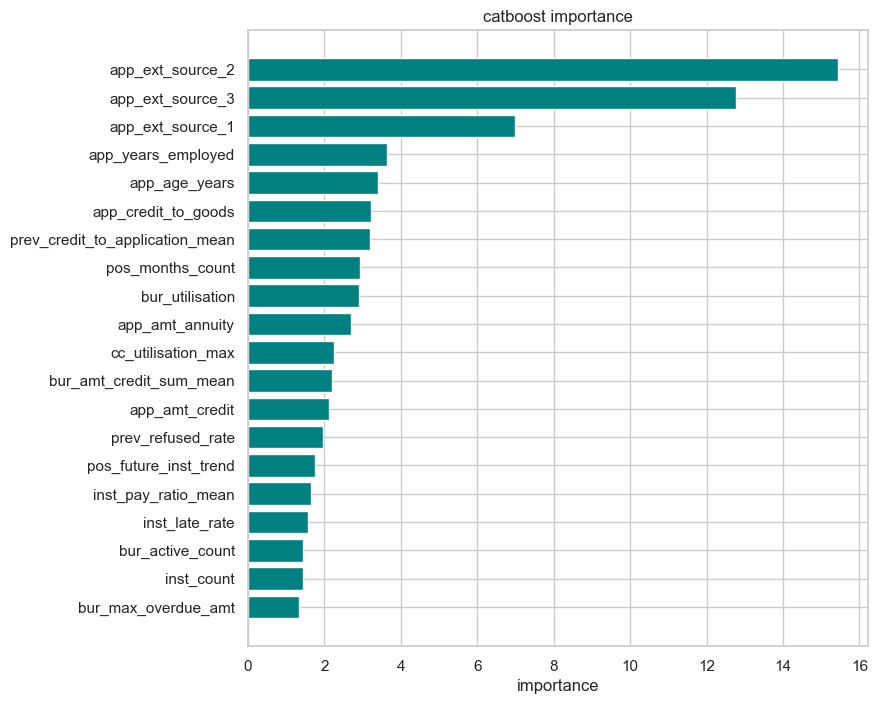

best booster on holdout: catboost


In [9]:
best_name = comparison.index[0]
gs = best_models[best_name]  # reuse the diagnostics helpers below
pre = gs.named_steps["preprocess"]
feat_names = list(pre.transform(search.X_train.iloc[:1]).columns)
model = gs.named_steps["model"]
importances = getattr(model, "feature_importances_", None)
if importances is not None:
    fig, ax = plt.subplots(figsize=(8, 8))
    plots.plot_feature_importance(feat_names, importances, top=20, ax=ax, title=f"{best_name} importance")
    plt.show()
print("best booster on holdout:", best_name)

## Takeaways

- Loss curves show each library converging; the validation minimum is the
  early-stopping point and guards against overfitting.
- The comparison table ranks tuned boosters by holdout AUC/KS - this
  selects the Stage-5 champion to port into `src/train.py` for Stage 6.
- Reported metrics in `reports/metrics.json` must come from the runnable
  pipeline, not these exploratory cells.